In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [23]:
df = pd.read_csv("Retail_Dataset_Cleaned.csv")

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [24]:
df.head()

,Store_ID,Store_Name,Brand_Name,Store_Type,City,City_Tier,Product_Name,Category,Sub_Category,Product_Stage,...,Brand_Loyalty,Brand_Awareness,Price_Competitiveness,Weather_Impact,Delivery_Time,Shipping_Cost,Month,Year,Quarter,Season
0,Bx_Pune_034,Brandx_India Superstore Pune,Brandx_India,Flagship,Pune,Tier1,Green Tea 100G,Groceries,Tea,Declining,...,70.8,75.7,Standard,Low,6.0,57.0,1,2022,Q1,Spring
1,Bx_Mumbai_023,Brandx_India Superstore Mumbai,Brandx_India,Street Store,Mumbai,Metro,White Sugar 1Kg,Groceries,Sugar,Declining,...,80.5,81.5,Competitive,Low,4.0,99.0,1,2022,Q1,Spring
2,Bx_Pune_073,Brandx_India Trends Pune,Brandx_India,Flagship,Pune,Tier1,Levi'S T-Shirt,Clothes,T-Shirts,Declining,...,68.5,76.7,Standard,Medium,4.0,101.0,1,2022,Q1,Spring
3,Bx_Chennai_061,Brandx_India Trends Chennai,Brandx_India,Mall Store,Chennai,Metro,Adidas Hoodie,Clothes,Jackets,New Launch,...,92.4,88.0,Competitive,Medium,5.0,79.0,1,2022,Q1,Spring
4,Bx_Chennai_033,Brandx_India Connect Chennai,Brandx_India,Mall Store,Chennai,Metro,Playstation 5,Gadgets,Gaming Consoles,Declining,...,82.9,89.5,Competitive,Low,2.0,110.0,1,2022,Q1,Spring


In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5146 entries, 0 to 5145
Data columns (total 47 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Store_ID               5146 non-null   str    
 1   Store_Name             5146 non-null   str    
 2   Brand_Name             5146 non-null   str    
 3   Store_Type             5146 non-null   str    
 4   City                   5146 non-null   str    
 5   City_Tier              5146 non-null   str    
 6   Product_Name           5146 non-null   str    
 7   Category               5146 non-null   str    
 8   Sub_Category           5146 non-null   str    
 9   Product_Stage          5146 non-null   str    
 10  Quantity_Available     5146 non-null   float64
 11  Units_Sold             5146 non-null   float64
 12  Unit_Price             5146 non-null   int64  
 13  Cost_Price             5146 non-null   int64  
 14  Revenue                5146 non-null   float64
 15  Profit_Margin  

In [26]:
df.columns

Index(['Store_ID', 'Store_Name', 'Brand_Name', 'Store_Type', 'City',
       'City_Tier', 'Product_Name', 'Category', 'Sub_Category',
       'Product_Stage', 'Quantity_Available', 'Units_Sold', 'Unit_Price',
       'Cost_Price', 'Revenue', 'Profit_Margin', 'Average_Order_Value',
       'Inventory_Turnover', 'Days_of_Stock', 'Customer_Segment',
       'Sales_Channel', 'Payment_Method', 'Supplier', 'Supplier_Rating',
       'Promotion_Type', 'Promotion_Impact', 'Max_Discount_Offered',
       'Return_Rate', 'Return_Reason', 'Customer_Satisfaction',
       'Online_Rating', 'Review_Count', 'Sales_Rep_Experience',
       'Sales_Rep_Rating', 'Market_Share', 'Competition_Level',
       'Competitor_Count', 'Brand_Loyalty', 'Brand_Awareness',
       'Price_Competitiveness', 'Weather_Impact', 'Delivery_Time',
       'Shipping_Cost', 'Month', 'Year', 'Quarter', 'Season'],
      dtype='str')

In [27]:
coupons = np.random.randint(1, 6, 1000)


In [28]:
coupon_counts = pd.Series(coupons).value_counts().sort_index()
print(coupon_counts)

1    201
2    213
3    199
4    197
5    190
Name: count, dtype: int64


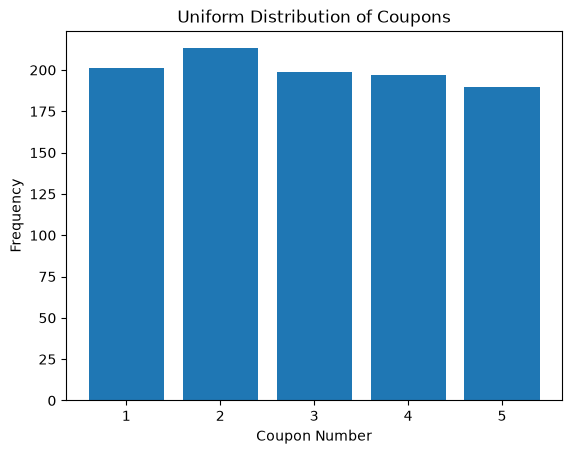

In [29]:
plt.bar(coupon_counts.index, coupon_counts.values)
plt.title("Uniform Distribution of Coupons")
plt.xlabel("Coupon Number")
plt.ylabel("Frequency")
plt.show()

In [30]:
probabilities = coupon_counts / coupon_counts.sum()
print(probabilities)

1    0.201
2    0.213
3    0.199
4    0.197
5    0.190
Name: count, dtype: float64


In [31]:
uniform_summary = pd.DataFrame({
    "Coupon": coupon_counts.index,
    "Probability": probabilities.values*100
})

uniform_summary

,Coupon,Probability
0,1,20.1
1,2,21.3
2,3,19.9
3,4,19.7
4,5,19.0


In [32]:
review_count = df["Review_Count"]

In [33]:
review_groups = pd.cut(review_count, bins=10)

In [34]:
review_distribution=review_groups.value_counts().sort_index()
print(review_distribution)

Review_Count
(9.51, 59.0]      506
(59.0, 108.0]     514
(108.0, 157.0]    464
(157.0, 206.0]    552
(206.0, 255.0]    533
(255.0, 304.0]    509
(304.0, 353.0]    517
(353.0, 402.0]    535
(402.0, 451.0]    512
(451.0, 500.0]    504
Name: count, dtype: int64


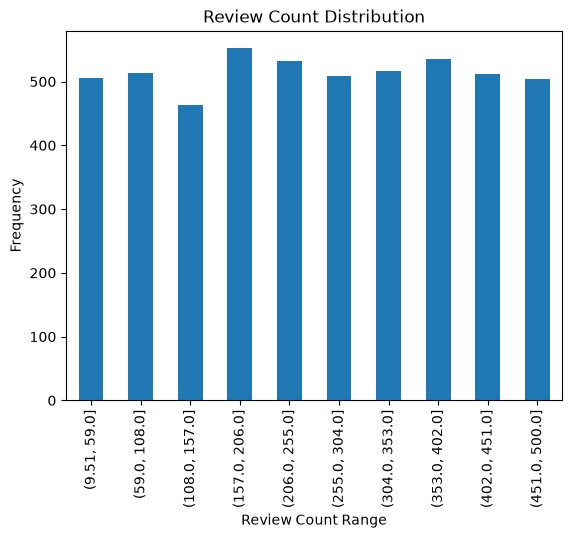

In [35]:
review_distribution.plot(kind='bar')
plt.title("Review Count Distribution")
plt.xlabel("Review Count Range")
plt.ylabel("Frequency")
plt.show()

In [36]:
review_probability = review_distribution / review_distribution.sum()
print(review_probability)

Review_Count
(9.51, 59.0]      0.098329
(59.0, 108.0]     0.099883
(108.0, 157.0]    0.090167
(157.0, 206.0]    0.107268
(206.0, 255.0]    0.103576
(255.0, 304.0]    0.098912
(304.0, 353.0]    0.100466
(353.0, 402.0]    0.103964
(402.0, 451.0]    0.099495
(451.0, 500.0]    0.097940
Name: count, dtype: float64


In [37]:
uniform_summary = pd.DataFrame({
    "Review Count Range": review_distribution.index.astype(str),
    "Frequency": review_distribution.values,
    "Probability": review_probability.values
})

uniform_summary

,Review Count Range,Frequency,Probability
0,"(9.51, 59.0]",506,0.098329
1,"(59.0, 108.0]",514,0.099883
2,"(108.0, 157.0]",464,0.090167
3,"(157.0, 206.0]",552,0.107268
4,"(206.0, 255.0]",533,0.103576
5,"(255.0, 304.0]",509,0.098912
6,"(304.0, 353.0]",517,0.100466
7,"(353.0, 402.0]",535,0.103964
8,"(402.0, 451.0]",512,0.099495
9,"(451.0, 500.0]",504,0.097940


In [39]:
import sys
print(sys.executable)

c:\Users\sanja\AppData\Local\Programs\Python\Python313\python.exe


In [40]:
%pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
    --------------------------------------- 0.5/36.6 MB 362.3 kB/s eta 0:01:40
    --------------------------------------- 0.5/36.6 MB 362.3 kB/s eta 0:01:40
    --------------------------------------- 0.5/36.6 MB 362.3 kB/s eta 0:01:40
    --------------------------------------- 0.5/36.6 MB 362.3 kB/s eta 0:01:40
    --------------------------------------- 0.8/36.6 MB 330.8 kB/s eta 0:01:49
    --------------------------------------- 0.8/36.6 MB 330.8 kB/s eta 0:01:49
    --------------------------------------- 0.8/36.6 MB 330.8 kB/s eta 0:01:49
    -----------------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom